In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


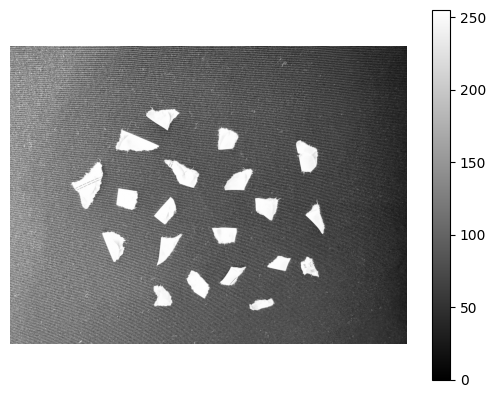

In [17]:
I = Image.open('/content/drive/MyDrive/class/IMG.jpeg').convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

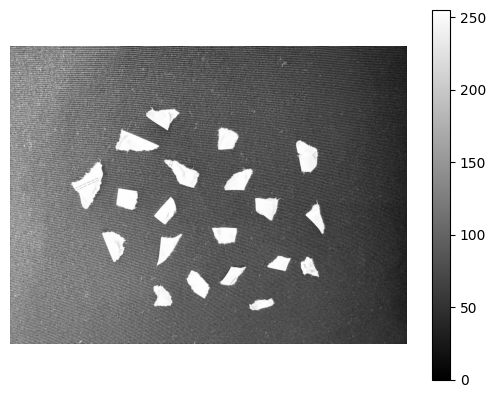

In [18]:
f_denoised = signal.medfilt2d(f,7)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

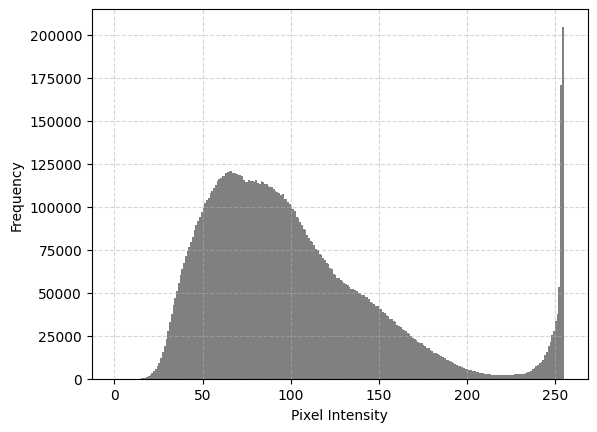

In [19]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

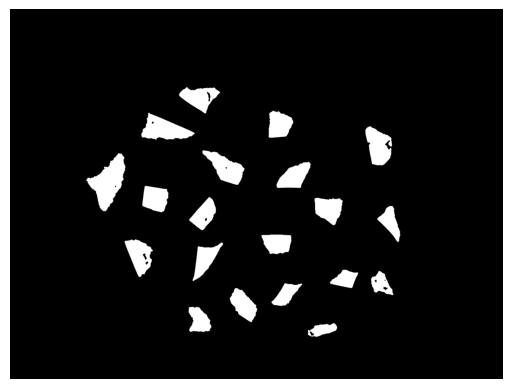

In [36]:
th_val = 230
f_mask = f_denoised > th_val
f_mask = nd.binary_closing(f_mask, iterations=5)
f_mask = nd.binary_opening(f_mask, iterations=5)
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

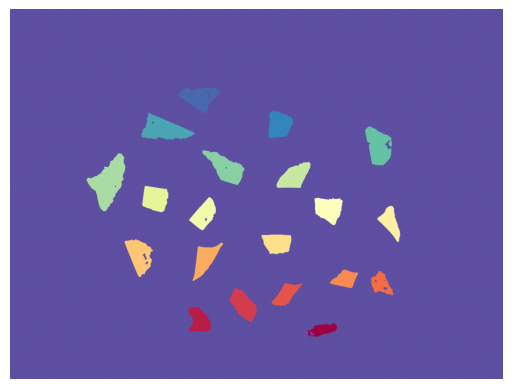

In [37]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [38]:
cc = np.zeros((nums,2))
for i in range(1,nums+1):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 38917
index: 2, number of pixels: 33975
index: 3, number of pixels: 53235
index: 4, number of pixels: 46730
index: 5, number of pixels: 46845
index: 6, number of pixels: 73571
index: 7, number of pixels: 36563
index: 8, number of pixels: 35526
index: 9, number of pixels: 31467
index: 10, number of pixels: 36409
index: 11, number of pixels: 25606
index: 12, number of pixels: 31251
index: 13, number of pixels: 41067
index: 14, number of pixels: 33829
index: 15, number of pixels: 20881
index: 16, number of pixels: 19810
index: 17, number of pixels: 23469
index: 18, number of pixels: 35028
index: 19, number of pixels: 27061
index: 20, number of pixels: 16234


In [40]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 5, # of pixels: 73571
the smallest component: index 19, # of pixels: 16234


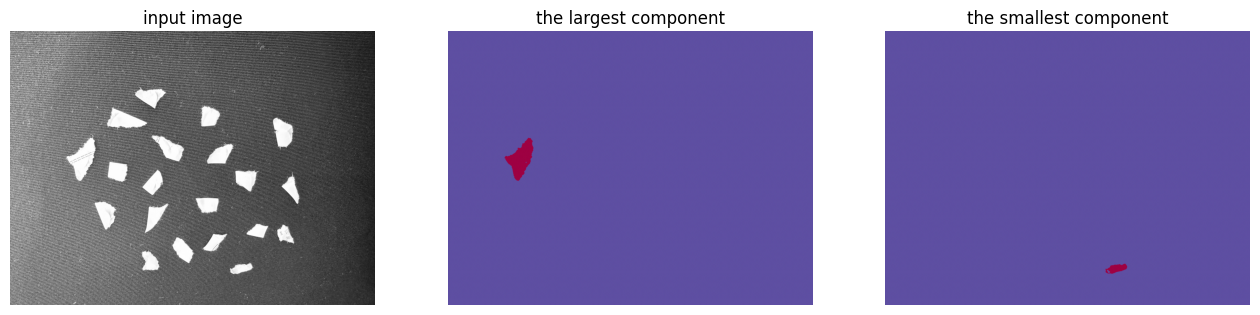

In [41]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()